# Walkthrough: Preparing data for METIS

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `b20b270c079a`](https://github.com/OJWatson/metis/tree/b20b270c079ad27a227a41b67828abcde7c74f87).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("b20b270c079ad27a227a41b67828abcde7c74f87")


Before training a surrogate, you need a dataset of simulator inputs (parameters)
paired with outputs (realisations). We will use the [SIRDS model](https://ojwatson.github.io/metis/basics/sirds-example.html)
to see how these are organised, then load and split the data with METIS.

The package includes a small SIRDS bank so you can follow the whole walkthrough
without running the simulator yourself. The same loading functions accept data
from your own simulator, whether it was written in Python, R or another language.

## Flattening a single realisation

A simulation table has one row per time point. For example, take the infected
counts from the first SIRDS realisation:

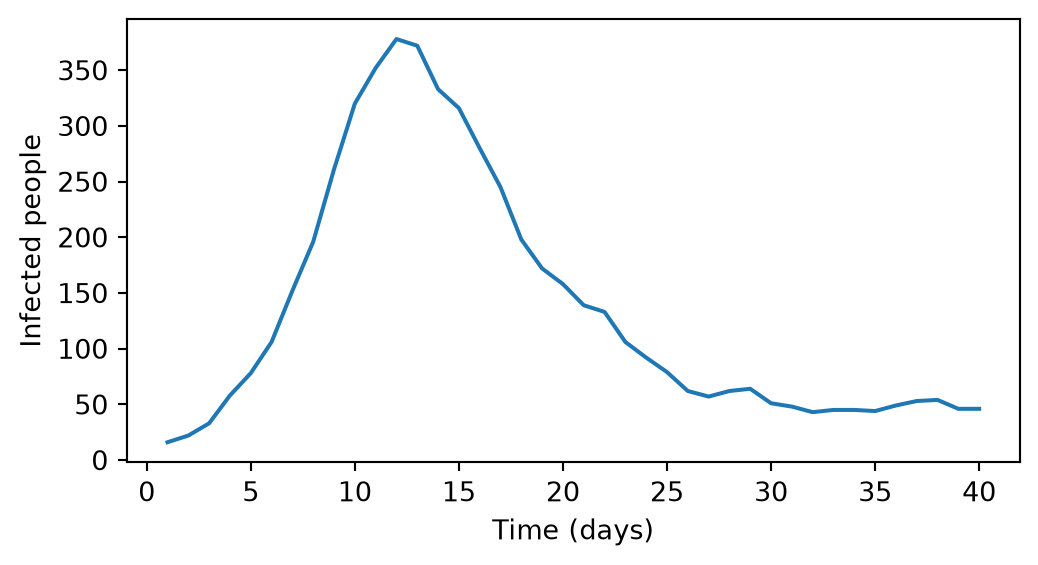

,t,I_t
0,1.0,16.0
1,2.0,22.0
2,3.0,33.0
3,4.0,58.0
4,5.0,78.0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from metis import SimulationDataset, load_example

example = load_example()
one_run = pd.DataFrame(example.outputs[0], columns=example.output_names)
one_run["t"] = example.times

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(one_run.t, one_run.I_t)
ax.set(xlabel="Time (days)", ylabel="Infected people")
plt.show()
one_run[["t", "I_t"]].head()

This realisation has 40 rows, one for each day. The other compartment counts
can be stored as additional columns on the same rows.

## Multiple SIRDS realisations

We also need to store the simulator inputs and distinguish realisations with
the same inputs. Input parameters become columns repeated along each
trajectory. A `rep` column identifies each realisation at that parameter
setting.

Here we turn the bundled bank's arrays into this long table:

In [2]:
frames = []
for inputs, outputs, rep in zip(
    example.inputs, example.outputs, example.replicate_ids
):
    frame = pd.DataFrame(outputs, columns=example.output_names)
    frame["t"] = example.times
    frame["rep"] = rep
    for name, value in zip(example.input_names, inputs):
        frame[name] = value
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
df[["I_0", "beta", "gamma", "omega", "mu", "rep", "t", "S_t", "I_t", "R_t", "D_t"]].head()

,I_0,beta,gamma,omega,mu,rep,t,S_t,I_t,R_t,D_t
0,0.012044,0.784743,0.218703,0.039243,0.029306,1,1.0,977.0,16.0,5.0,2.0
1,0.012044,0.784743,0.218703,0.039243,0.029306,1,2.0,966.0,22.0,9.0,3.0
2,0.012044,0.784743,0.218703,0.039243,0.029306,1,3.0,950.0,33.0,14.0,3.0
3,0.012044,0.784743,0.218703,0.039243,0.029306,1,4.0,919.0,58.0,19.0,4.0
4,0.012044,0.784743,0.218703,0.039243,0.029306,1,5.0,880.0,78.0,33.0,9.0


The same `rep` values can be reused at different parameter settings. All five
realisations at one setting share their input values; their outputs differ
because the simulator is stochastic.

## Sampling the parameter space

When building a simulation bank, consider which regions of the parameter space
you need to cover. A simulator may be especially sensitive in some regions,
and parameters may be physically constrained. The SIRDS example samples inputs
uniformly within specified ranges. Latin hypercube sampling is another common
choice for spreading a limited number of simulations across the input space.

The plot below shows the 100 settings already present in our bank. These are
the same settings we will use for training, rather than another example dataset.

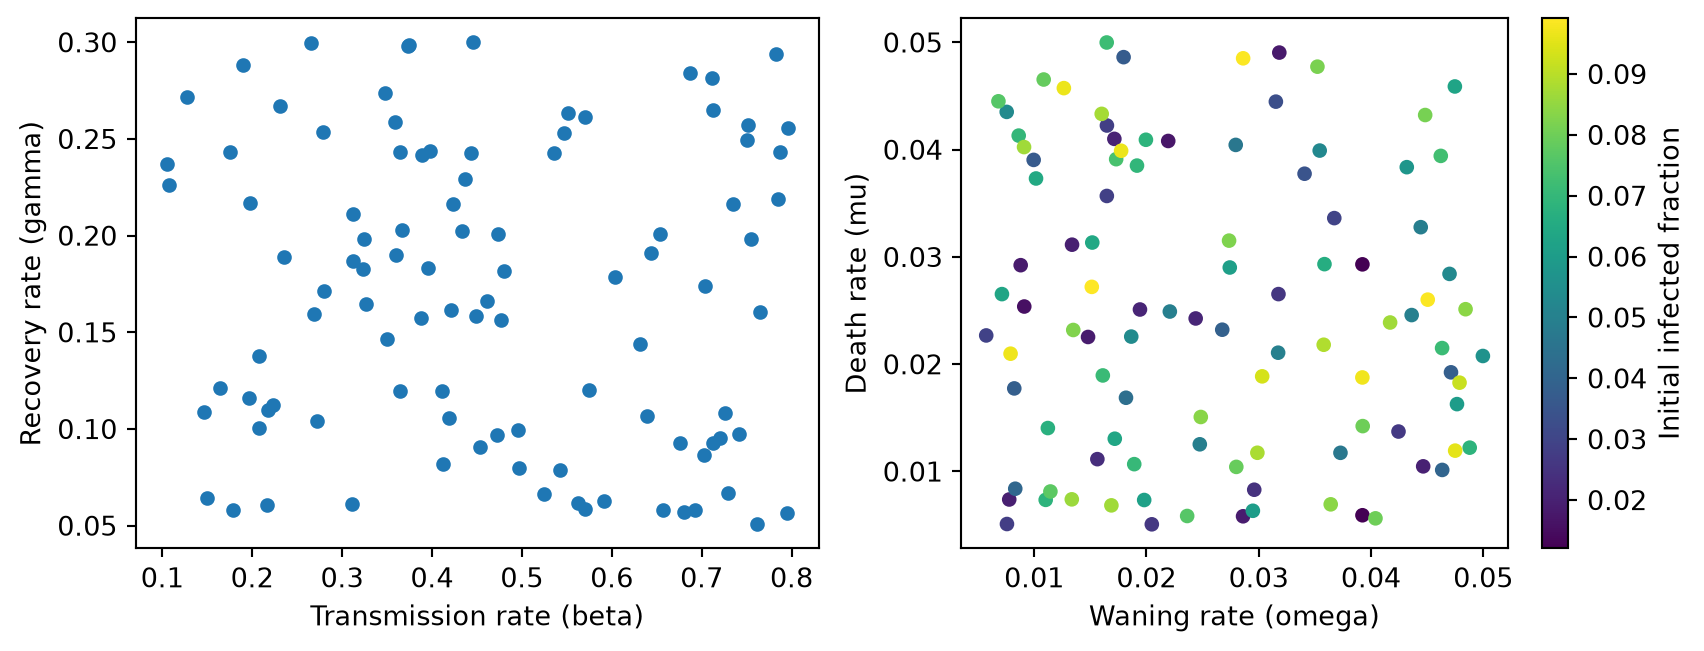

100 settings × 5 realisations × 40 days = 20,000 rows


In [3]:
#| fig-cap: "Bundled SIRDS bank: 100 parameter settings, with five stochastic realisations at each setting."
settings = df[list(example.input_names)].drop_duplicates()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].scatter(settings.beta, settings.gamma, s=20)
axes[0].set(xlabel="Transmission rate (beta)", ylabel="Recovery rate (gamma)")
axes[1].scatter(settings.omega, settings.mu, c=settings.I_0, s=20, cmap="viridis")
axes[1].set(xlabel="Waning rate (omega)", ylabel="Death rate (mu)")
fig.colorbar(axes[1].collections[0], ax=axes[1], label="Initial infected fraction")
fig.tight_layout()
plt.show()
print(f"{len(settings)} settings × 5 realisations × 40 days = {len(df):,} rows")

*Bundled SIRDS bank: 100 parameter settings, with five stochastic realisations at each setting.*

## Loading the full dataset

Tell METIS which columns contain the inputs and outputs:

In [4]:
input_names = ["I_0", "beta", "gamma", "omega", "mu"]
output_names = ["S_t", "I_t", "R_t", "D_t"]
bank = SimulationDataset.from_frame(df, inputs=input_names, outputs=output_names)
print("Inputs (realisations, parameters):", bank.inputs.shape)
print("Outputs (realisations, time points, compartments):", bank.outputs.shape)

Inputs (realisations, parameters): (500, 5)
Outputs (realisations, time points, compartments): (500, 40, 4)


`from_frame` accepts pandas or Polars data frames. It checks that values are
finite, that there are no duplicate observations, and that every realisation
has the same complete time grid. The default time and replicate column names
are `t` and `rep`; use the `time=` and `replicate=` arguments if yours differ.

You can save the table as a Parquet file and load it directly in another session:

In [5]:
df.to_parquet("sirds_data.parquet", index=False)
bank = SimulationDataset.from_parquet(
    "sirds_data.parquet", inputs=input_names, outputs=output_names
)
print(f"Loaded {len(bank)} SIRDS realisations")

Loaded 500 SIRDS realisations


For your own model, replace `df` or the Parquet path and supply your input and
output column names. Keep each input constant within a realisation, and keep
all realisations on the same time grid.

## Splitting for training and evaluation

We need some simulations to fit the model and others to check it. METIS can
make a reproducible split:

In [6]:
split = bank.split(validation_fraction=0.2, test_fraction=0.2, seed=42)
pd.DataFrame([
    {"Partition": name, "Parameter settings": len(set(part.group_keys)),
     "Realisations": len(part)}
    for name, part in [
        ("Training", split.train), ("Validation", split.validation), ("Test", split.test)
    ]
])

,Partition,Parameter settings,Realisations
0,Training,60,300
1,Validation,20,100
2,Test,20,100


The training set is used to fit the neural network. The validation set helps
choose training settings and the best saved weights. The test set is kept
aside for the final check. All realisations at the same inputs stay together,
so the model must predict at parameter settings it has not seen in training.
Scaling is fitted on the training data automatically when you call `fit`.

Next, [install METIS in your own project](https://ojwatson.github.io/metis/basics/installing_metis.html), then follow
the [Hydra crash course](https://ojwatson.github.io/metis/basics/hydra.html) before training. If you are using Colab,
the notebook setup cell handles installation for you.